# From Wall-Shear Stress to Near-Wall Velocity (Turbulent Channel Flow)

** This version works directly from the raw HDF5
snapshots with this objective:

```text
Given only the wall-shear stress tau_w(x), can we tell what the flow is doing
at y+ = 5 and y+ = 10 -- i.e. u(x; y+=5) and u(x; y+=10)?
```

This is a genuinely different question from "predict the wall from off-wall
data" : here we ask whether the single scalar quantity every engineering RANS/LES wall model already has access to (the wall stress) is informative enough to recover near-wall values 

**Data.** Each HDF5 file is a single (y, x) plane of the streamwise velocity
`u`, at one fixed spanwise index `z`, for one time snapshot, from the
`P125_83pi` channel-flow DNS ($Re_\tau \approx 125$ nominal, bulk Reynolds number `Re=2100` stored in the file). The wall-normal grid
`y` is **not** uniform (clustered near the walls) and is stored alongside `u`
in every file.

**Doubling the wall samples via symmetry.** A channel is statistically
symmetric about its centerline. Instead of only using the wall at `y[0]`, we
also mirror the upper half of the domain and treat `y[-1]` as a second,
independent wall -- doubling the number of usable near-wall samples per
snapshot for free.

**No TFRecords, no streaming.** Each sample is a 1D signal of `n_x = 384`
points, so even a few thousand snapshots comfortably fit in memory. This
notebook builds the dataset directly as NumPy arrays, rather than a streaming
`tf.data` pipeline.


# Stage 1 — From wall shear stress to near-wall velocity with a 1-D U-Net

**Portfolio project: how much of the near-wall flow can the wall shear stress tell us?**

Wall models in RANS and LES see only the wall: the shear stress. This notebook asks how much that one quantity tells about the flow just above it. From 5,777 y–x planes of the streamwise velocity in a turbulent channel-flow simulation (Re_τ ≈ 125, 201 × 384 points per plane), it computes the wall gradient τ_w(x) at both walls with a second-order one-sided difference on the stretched grid, and trains a 1-D U-Net (four levels, 677,122 weights) to map the 384-point τ_w(x) to u(x) at y+ ≈ 5 and 10. It compares the result with the viscous-sublayer linear law. I solve the notebook's five experiments (more heights, a local friction velocity, spanwise planes against model size under a snapshot-wise split, a gradient attribution, much smaller models), repeat every training with the seeds 0, 1 and 2, and record a training animation.

**How it connects.** Stage 2 holds the comparison to stricter terms: the correct linear law, ridge regression on the same input, targets up to the channel centre, and splits that hold out later snapshots or unseen spanwise planes.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, 2026-10-13, CPU only: every network here trains faster on the CPU than on the Apple GPU). Afterwards I changed only text for this repository: this cell and the paths cell, the path lines (planes from `../release_assets/u_yx_planes_h5/`, model to `../models/01_wall_to_near_wall_unet/`, tables to `../results/01_wall_to_near_wall_unet/`, animation to `../animations/01_*`), comments, labels and printed text. Two quirks are kept as written: the linear-law baseline leaves out the viscosity (τ_w here is du/dy, so the friction velocity is √(ν·|du/dy|)) and takes the top-wall gradient with the opposite sign, so its error is about a thousand times the U-Net's; and the random split puts both walls and all spanwise planes of a snapshot on both sides. Stage 2 corrects both comparisons.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
PLANES = Path("../release_assets/u_yx_planes_h5")   # the 5,777 planes, from the unet-turbulent-fields release (README)
for p in (Path("../models/01_wall_to_near_wall_unet/checkpoints"), Path("../results/01_wall_to_near_wall_unet/exercises"), Path("../animations")):
    p.mkdir(parents=True, exist_ok=True)
print("planes found:", len(list(PLANES.glob("P125_83pi.*.h5"))) if PLANES.is_dir() else 0)

In [1]:
# Device report. CPU only: one training step inside model.fit (batch 32, median of 30 steps after 10 warm-up;
# ../results/02_height_and_generalisation/device_timing_*.csv), CPU vs Apple GPU in ms: 1-D U-Net 15.6 vs 81.2, 5-output U-Net 15.6 vs 88.8,
# 32-filter U-Net 39.6 vs 94.0, single conv block 1.3 vs 6.2, small dense network 0.74 vs 4.5 -> the CPU is faster for every network.
import tensorflow as tf, platform
tf.config.set_visible_devices([], "GPU")
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices(), "| visible to TensorFlow:", tf.config.get_visible_devices())

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | visible to TensorFlow: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


# 1. Environment

Required packages:

```bash
pip install h5py numpy tensorflow matplotlib scikit-learn
```


In [2]:
# =========================================================
# Import libraries
# =========================================================

from pathlib import Path
import json

import h5py
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)
print("Current working directory:", Path.cwd())


TensorFlow version: 2.18.1
Current working directory: <repository>/notebooks


# 2. Optional: Google Colab Setup


In [3]:
# =========================================================
# Check whether we are running in Google Colab
# =========================================================

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    # [original] drive.mount("/content/drive")
    pass  # Google Drive is not mounted: the planes come from the local merged folder (see the data_dir cell)
    print("Google Drive mounted.")
else:
    print("This is not Google Colab.")
    print("Current working directory:")
    print(Path.cwd())


Running in Google Colab: False
This is not Google Colab.
Current working directory:
<repository>/notebooks


# 3. Define Data Paths and List Available Files

**Adjust `data_dir` and `file_glob` below to match your actual directory.**
Since every HDF5 file here is a single (y, x) plane at one fixed z and one
time snapshot, `file_glob` should match *all* such files (one per snapshot).
Run this cell first and check that `matched_files` is not empty and looks
right before continuing.


In [4]:
# =========================================================
# Define data paths and list matching files
# =========================================================

if IN_COLAB:
    data_dir = Path("/content/drive/<Drive folder>/wall-shear-to-near-wall-velocity/release_assets/u_yx_planes_h5")
else:
    data_dir = Path("../release_assets/u_yx_planes_h5")  # path line: the planes from the release (README)

# ADJUST this glob pattern to match your actual file names.

file_glob = "P125_83pi.*.h5"

matched_files = sorted(data_dir.glob(file_glob))

print("Data directory:", data_dir)
print("Glob pattern:  ", file_glob)
print("Number of matched files:", len(matched_files))
print("\nFirst 5 matches:")
for f in matched_files[:5]:
    print(" ", f.name)

if len(matched_files) == 0:
    print("\nNo files matched -- list the directory manually to find the correct pattern:")
    for f in sorted(data_dir.iterdir())[:20]:
        print(" ", f.name)


Data directory: ../release_assets/u_yx_planes_h5
Glob pattern:   P125_83pi.*.h5
Number of matched files: 5777

First 5 matches:
  P125_83pi.30000.000.h5
  P125_83pi.30000.001.h5
  P125_83pi.30000.002.h5
  P125_83pi.30000.003.h5
  P125_83pi.30000.004.h5


# 4. Inspect One File

Sanity check: confirm the structure matches what we expect (`u` shape
`(n_y, n_x)`, `y` shape `(n_y,)`, non-uniform grid).


In [5]:
# =========================================================
# Inspect one file
# =========================================================

with h5py.File(matched_files[0], "r") as f:
    u_sample = f["u"][:]
    y_sample = f["y"][:]
    attrs_sample = dict(f.attrs)

print("u shape:", u_sample.shape, " (n_y, n_x)")
print("y shape:", y_sample.shape)
print("y[0], y[-1]:", y_sample[0], y_sample[-1])
print("y[:5]: ", y_sample[:5])
print("Grid spacing dy[:5]:", np.diff(y_sample)[:5], " (non-uniform: not all equal)")
print("\nAttributes:")
for k, v in attrs_sample.items():
    print(f"  {k}: {v}")

n_y, n_x = u_sample.shape
re_tau_nominal = 125.0  # nominal Re_tau for the P125_83pi case


u shape: (201, 384)  (n_y, n_x)
y shape: (201,)
y[0], y[-1]: -1.0 1.0
y[:5]:  [-1.         -0.99725468 -0.99422326 -0.99091432 -0.98733595]
Grid spacing dy[:5]: [0.00274532 0.00303141 0.00330895 0.00357837 0.00384008]  (non-uniform: not all equal)

Attributes:
  Re: 2100.0
  alp: 0.25
  bet: 0.6666666666666666
  compression: gzip
  compression_opts: 4
  dataset_layout: u[y_index, x_index]
  description: Single y-x plane of the u velocity component.
  dtype: float32
  mx: 384
  my: 201
  mz: 288
  n_x: 384
  n_y: 201
  n_z_total: 288
  original_axis_order: (y, z, x)
  original_dataset_name: u
  original_shape: (201, 288, 384)
  output_axis_order: (y, x)
  output_dataset_name: u
  plane_shape: (201, 384)
  plane_type: y-x plane at fixed z index
  snapshot_number: 30000
  source_file: P125_83pi.30000.h5.uvw
  source_path: <original simulation folder>\P125_83pi.30000.h5.uvw
  time: 66.25142812728882
  variable: u
  vcon: 0.0
  z_index: 0
  z_label: 000


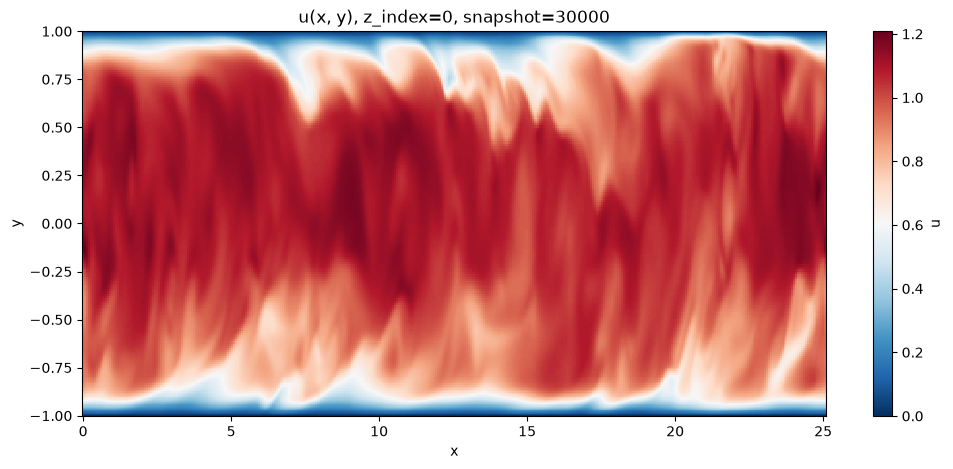

In [6]:
# =========================================================
# Plot the 2D (y, x) velocity field
# =========================================================

Lx = 2 * np.pi / attrs_sample["alp"]  # streamwise domain length (8*pi for this case)
x_sample = np.linspace(0, Lx, n_x, endpoint=False)

X, Y = np.meshgrid(x_sample, y_sample)  # both shape (n_y, n_x), matches u_sample

fig, ax = plt.subplots(figsize=(12, 5))

pcm = ax.pcolormesh(X, Y, u_sample, cmap="RdBu_r", shading="auto")
fig.colorbar(pcm, ax=ax, label="u")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"u(x, y), z_index={attrs_sample['z_index']}, snapshot={attrs_sample['snapshot_number']}")

plt.show()

# 5. Computing $\tau_w(x)$ on a Non-Uniform Grid

One-sided, second-order finite-difference approximation of the wall-normal
derivative at a wall, using the first three grid points **away from that
wall** and their (unequal) spacings $h_1 = y_1 - y_0$, $h_2 = y_2 - y_1$:

$$
\left.\frac{\partial u}{\partial y}\right|_{\text{wall}} \approx
-\frac{2h_1+h_2}{h_1(h_1+h_2)}u_0 + \frac{h_1+h_2}{h_1 h_2}u_1 - \frac{h_1}{h_2(h_1+h_2)}u_2
$$

We define $\tau_w$ here simply as this gradient, in whatever units `u` and `y`
are already stored in -- the learning task doesn't need it converted to
absolute physical units, only to be a consistent, well-defined target.

Applied twice per snapshot: once at `y[0]` (bottom wall, points `0,1,2` in
order), and once at `y[-1]` (top wall, points `-1,-2,-3`, i.e. walking into
the fluid from the *other* end) -- giving two independent wall samples per
snapshot via the channel's statistical symmetry.


In [7]:
# =========================================================
# One-sided second-order derivative at a wall, non-uniform grid
# =========================================================

def wall_gradient(u_wall_to_inner, y_wall_to_inner):
    """
    Second-order one-sided derivative at a wall on a non-uniform grid.

    Parameters
    ----------
    u_wall_to_inner : array, shape (3, n_x)
        u at the first 3 grid points starting AT the wall and moving into
        the fluid (u_wall_to_inner[0] is the value at the wall itself).
    y_wall_to_inner : array, shape (3,)
        The corresponding y coordinates, same ordering (wall first).

    Returns
    -------
    dudy : array, shape (n_x,)
    """

    h1 = y_wall_to_inner[1] - y_wall_to_inner[0]
    h2 = y_wall_to_inner[2] - y_wall_to_inner[1]

    c0 = -(2 * h1 + h2) / (h1 * (h1 + h2))
    c1 = (h1 + h2) / (h1 * h2)
    c2 = -h1 / (h2 * (h1 + h2))

    dudy = c0 * u_wall_to_inner[0] + c1 * u_wall_to_inner[1] + c2 * u_wall_to_inner[2]

    return dudy


def compute_tau_w_both_walls(u, y):
    """
    Compute tau_w(x) at both walls of a channel snapshot, exploiting
    statistical symmetry: bottom wall at y[0], top wall (mirrored) at y[-1].

    u : array, shape (n_y, n_x)
    y : array, shape (n_y,)

    Returns
    -------
    tau_w_bottom, tau_w_top : arrays, shape (n_x,)
    """

    tau_w_bottom = wall_gradient(u[0:3, :], y[0:3])

    # Top wall: walk from y[-1] INTO the fluid, i.e. reverse order
    u_top = u[-1:-4:-1, :]      # u[-1], u[-2], u[-3]
    y_top = y[-1:-4:-1]         # y[-1], y[-2], y[-3]
    tau_w_top = wall_gradient(u_top, y_top)

    return tau_w_bottom, tau_w_top


tau_w_bottom_sample, tau_w_top_sample = compute_tau_w_both_walls(u_sample, y_sample)
print("tau_w_bottom(x) stats: mean={:.4f} std={:.4f}".format(
    tau_w_bottom_sample.mean(), tau_w_bottom_sample.std()))
print("tau_w_top(x)    stats: mean={:.4f} std={:.4f}".format(
    tau_w_top_sample.mean(), tau_w_top_sample.std()))


tau_w_bottom(x) stats: mean=7.7687 std=1.7867
tau_w_top(x)    stats: mean=-9.2545 std=4.8642


# 6. Locating $y^+ = 5$ and $y^+ = 10$ on the Grid

Using the nominal $Re_\tau = 125$ for this case, and assuming `y` spans the
full channel height (wall to wall), the half-channel height is
$h = (y[-1] - y[0]) / 2$, and

$$
y^+(y) = \frac{y_{\text{from wall}}}{h}\, Re_\tau.
$$

We find the grid index closest to $y^+=5$ and $y^+=10$ **once** (the grid is
the same for every snapshot), for both walls (mirrored for the top one).
**Sanity-check the printed $y^+$ values below** -- if they are wildly off from
5 and 10, the assumption that `y` spans the full channel height (rather than,
say, only the half-channel, or a different normalization) is wrong, and this
cell needs adjusting.


In [8]:
# =========================================================
# Find grid indices closest to y+ = 5 and y+ = 10, both walls
# =========================================================

half_height = (y_sample[-1] - y_sample[0]) / 2.0

def y_plus_from_wall(y, wall="bottom"):
    if wall == "bottom":
        y_from_wall = y - y_sample[0]
    else:
        y_from_wall = y_sample[-1] - y
    return y_from_wall / half_height * re_tau_nominal


y_plus_targets = [5.0, 10.0]

idx_bottom = []
idx_top = []

for target in y_plus_targets:
    yp_bottom = y_plus_from_wall(y_sample, wall="bottom")
    idx_b = int(np.argmin(np.abs(yp_bottom - target)))
    idx_bottom.append(idx_b)

    yp_top = y_plus_from_wall(y_sample, wall="top")
    idx_t = int(np.argmin(np.abs(yp_top - target)))
    idx_top.append(idx_t)

    print(f"y+ target = {target:5.1f}   "
          f"bottom: grid index {idx_b:3d}, actual y+ = {yp_bottom[idx_b]:.2f}   "
          f"top: grid index {idx_t:3d}, actual y+ = {yp_top[idx_t]:.2f}")


y+ target =   5.0   bottom: grid index  10, actual y+ = 4.92   top: grid index 190, actual y+ = 4.92
y+ target =  10.0   bottom: grid index  17, actual y+ = 10.08   top: grid index 183, actual y+ = 10.08


# 7. Build the Full Dataset from All Snapshot Files

For every file: compute $\tau_w(x)$ and $[u(x;y^+{=}5), u(x;y^+{=}10)]$ at
**both** walls, giving 2 samples per file.


In [9]:
# =========================================================
# Build (input, target) pairs from all snapshot files
# =========================================================

X_list = []
Y_list = []

for i, file_path in enumerate(matched_files):
    with h5py.File(file_path, "r") as f:
        u = f["u"][:]
        y = f["y"][:]

    tau_w_bottom, tau_w_top = compute_tau_w_both_walls(u, y)

    u_target_bottom = np.stack([u[idx_bottom[0], :], u[idx_bottom[1], :]], axis=-1)  # (n_x, 2)
    u_target_top = np.stack([u[idx_top[0], :], u[idx_top[1], :]], axis=-1)

    X_list.append(tau_w_bottom[:, None])   # (n_x, 1)
    Y_list.append(u_target_bottom)

    X_list.append(tau_w_top[:, None])
    Y_list.append(u_target_top)

    if (i + 1) % 200 == 0:
        print(f"Processed {i + 1} / {len(matched_files)} files "
              f"({2 * (i + 1)} samples so far)")

X = np.stack(X_list, axis=0).astype(np.float32)  # (n_samples, n_x, 1)
Y = np.stack(Y_list, axis=0).astype(np.float32)  # (n_samples, n_x, 2)

print("\nX shape (tau_w input):        ", X.shape)
print("Y shape (u at y+=5, y+=10):    ", Y.shape)


Processed 200 / 5777 files (400 samples so far)


Processed 400 / 5777 files (800 samples so far)


Processed 600 / 5777 files (1200 samples so far)


Processed 800 / 5777 files (1600 samples so far)


Processed 1000 / 5777 files (2000 samples so far)


...

Processed 5000 / 5777 files (10000 samples so far)


Processed 5200 / 5777 files (10400 samples so far)


Processed 5400 / 5777 files (10800 samples so far)


Processed 5600 / 5777 files (11200 samples so far)



X shape (tau_w input):         (11554, 384, 1)
Y shape (u at y+=5, y+=10):     (11554, 384, 2)


# 8. Normalize and Split into Train/Validation


In [10]:
# =========================================================
# Normalize (input and target separately) and split
# =========================================================

input_mean = X.mean(axis=(0, 1), keepdims=True)
input_std = X.std(axis=(0, 1), keepdims=True) + 1e-8

target_mean = Y.mean(axis=(0, 1), keepdims=True)
target_std = Y.std(axis=(0, 1), keepdims=True) + 1e-8

X_norm = (X - input_mean) / input_std
Y_norm = (Y - target_mean) / target_std

X_trn, X_val, Y_trn, Y_val = train_test_split(
    X_norm, Y_norm, test_size=0.2, random_state=24, shuffle=True
)

print("Training samples:  ", X_trn.shape[0])
print("Validation samples:", X_val.shape[0])

padded_length = X.shape[1]
in_channels = X.shape[2]
out_channels = Y.shape[2]
print("\npadded_length / in_channels / out_channels:", padded_length, in_channels, out_channels)


Training samples:   9243
Validation samples: 2311

padded_length / in_channels / out_channels: 384 1 2


# 9. Visualize One Sample


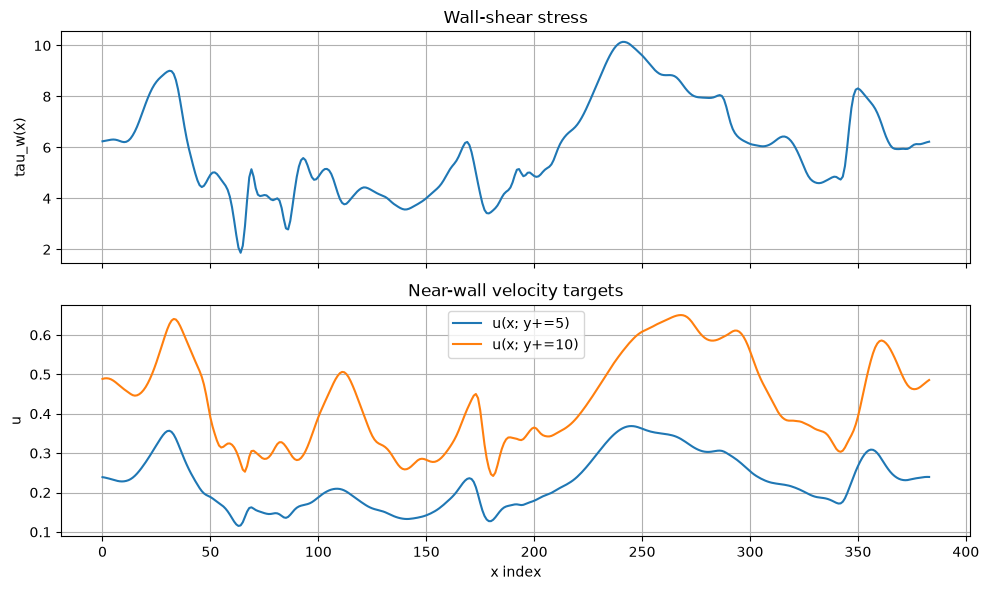

In [11]:
# =========================================================
# Visualize one training sample (denormalized, physical units)
# =========================================================

idx = 0

x_phys = X_trn[idx, :, 0] * input_std[0, 0, 0] + input_mean[0, 0, 0]
y5_phys = Y_trn[idx, :, 0] * target_std[0, 0, 0] + target_mean[0, 0, 0]
y10_phys = Y_trn[idx, :, 1] * target_std[0, 0, 1] + target_mean[0, 0, 1]

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(x_phys)
ax[0].set_ylabel("tau_w(x)")
ax[0].set_title("Wall-shear stress")
ax[0].grid(True)

ax[1].plot(y5_phys, label="u(x; y+=5)")
ax[1].plot(y10_phys, label="u(x; y+=10)")
ax[1].set_xlabel("x index")
ax[1].set_ylabel("u")
ax[1].set_title("Near-wall velocity targets")
ax[1].legend()
ax[1].grid(True)

fig.tight_layout()
plt.show()


# 10. Baseline: Viscous-Sublayer Linear Law

Close to the wall, the mean velocity profile is (to leading order) linear in
wall units: $u^+ \approx y^+$, with $u_\tau = \sqrt{|\tau_w|}$ (using the sign
of $\tau_w$ to keep the physical direction). We use this to predict
$u(y^+{=}5)$ and $u(y^+{=}10)$ directly from $\tau_w(x)$, **with no training at
all**, and expect it to degrade more at $y^+=10$ than at $y^+=5$, since the
linear sublayer is usually considered valid only up to $y^+ \lesssim 5$.


In [12]:
# =========================================================
# Viscous-sublayer linear-law baseline: u(y+) ~ u_tau * y+
# =========================================================

def linear_law_predict(tau_w_phys, y_plus_targets):
    """
    tau_w_phys: array (..., n_x), physical (unnormalized) tau_w
    Returns predictions with shape (..., n_x, len(y_plus_targets))
    """
    u_tau = np.sign(tau_w_phys) * np.sqrt(np.abs(tau_w_phys))
    preds = np.stack([u_tau * yp for yp in y_plus_targets], axis=-1)
    return preds


X_val_phys = X_val[..., 0] * input_std[0, 0, 0] + input_mean[0, 0, 0]
Y_val_phys = Y_val * target_std + target_mean

Y_val_baseline = linear_law_predict(X_val_phys, y_plus_targets)

baseline_mae_per_target = np.mean(np.abs(Y_val_baseline - Y_val_phys), axis=(0, 1))

for target, mae in zip(y_plus_targets, baseline_mae_per_target):
    print(f"Linear-law baseline MAE at y+={target:.0f}: {mae:.4f}")


Linear-law baseline MAE at y+=5: 13.5757
Linear-law baseline MAE at y+=10: 27.1523


# 11. U-Net Architecture: 1D Building Blocks

The usual `conv_block`/`encoder_block`/`decoder_block` U-Net pattern, in 1D since $x$ is the only spatial axis available.


In [13]:
# =========================================================
# U-Net building blocks, 1D version
# =========================================================


def conv_block(x, filters, kernel_size=3, activation="relu", padding="same", dropout_rate=0.0):
    x = tf.keras.layers.Conv1D(filters, kernel_size, activation=activation,
                                padding=padding, kernel_initializer="he_normal")(x)
    x = tf.keras.layers.Conv1D(filters, kernel_size, activation=activation,
                                padding=padding, kernel_initializer="he_normal")(x)
    if dropout_rate > 0.0:
        x = tf.keras.layers.Dropout(dropout_rate)(x)
    return x


def encoder_block(x, filters, dropout_rate=0.0):
    skip = conv_block(x, filters, dropout_rate=dropout_rate)
    down = tf.keras.layers.MaxPooling1D(pool_size=2)(skip)
    return skip, down


def decoder_block(x, skip, filters, dropout_rate=0.0):
    x = tf.keras.layers.Conv1DTranspose(filters, kernel_size=2, strides=2, padding="same")(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = conv_block(x, filters, dropout_rate=dropout_rate)
    return x


# 12. Assemble, Train and Save the U-Net


In [14]:
# =========================================================
# Assemble the 1D U-Net
# =========================================================

def create_unet_wall_to_nearwall(input_shape, output_channels, base_filters=16,
                                  dropout_rate=0.0, learning_rate=1e-4):

    inputs = tf.keras.layers.Input(shape=input_shape)

    skip1, x = encoder_block(inputs, base_filters, dropout_rate)
    skip2, x = encoder_block(x, base_filters * 2, dropout_rate)
    skip3, x = encoder_block(x, base_filters * 4, dropout_rate)
    skip4, x = encoder_block(x, base_filters * 8, dropout_rate)

    x = conv_block(x, base_filters * 16, dropout_rate=dropout_rate)

    x = decoder_block(x, skip4, base_filters * 8, dropout_rate)
    x = decoder_block(x, skip3, base_filters * 4, dropout_rate)
    x = decoder_block(x, skip2, base_filters * 2, dropout_rate)
    x = decoder_block(x, skip1, base_filters, dropout_rate)

    outputs = tf.keras.layers.Conv1D(output_channels, kernel_size=1, activation="linear")(x)

    model = tf.keras.Model(inputs, outputs, name="UNet1D_WallToNearWall")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="mse",
        metrics=["mae"]
    )
    return model


input_shape = (padded_length, in_channels)

unet_model = create_unet_wall_to_nearwall(
    input_shape=input_shape,
    output_channels=out_channels,
    base_filters=16
)

unet_model.summary()


Model: "UNet1D_WallToNearWall"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 384, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 384, 16)   │         64 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 384, 16)   │        784 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 192, 16)   │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 192, 32)   │      1,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 192, 32)   │      3,104 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 96, 32)    │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 96, 64)    │      6,208 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 96, 64)    │     12,352 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 48, 64)    │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 48, 128)   │     24,704 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 48, 128)   │     49,280 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 24, 128)   │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 24, 256)   │     98,560 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 24, 256)   │    196,864 │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_transpose    │ (None, 48, 128)   │     65,664 │ conv1d_9[0][0]    │
│ (Conv1DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48, 256)   │          0 │ conv1d_transpose… │
│ (Concatenate)       │                   │            │ conv1d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 48, 128)   │     98,432 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 48, 128)   │     49,280 │ conv1d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_transpose_1  │ (None, 96, 64)    │     16,448 │ conv1d_11[0][0]   │
│ (Conv1DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 96, 128)   │          0 │ conv1d_transpose

 Total params: 677,122 (2.58 MB)

 Trainable params: 677,122 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

**Hook before the training cell.** Checkpoints for the notebook's U-Net training (best model by validation loss, periodic checkpoint every 30 epochs, in `../models/01_wall_to_near_wall_unet/checkpoints/`) and a snapshot collector for the training animation, so the animation comes from the base run (no second training). The training cell adds these callbacks to the base early stopping and learning-rate schedule; nothing else changes.

In [15]:
import os
from pathlib import Path
EX_CKPT = Path("../models/01_wall_to_near_wall_unet/checkpoints"); EX_CKPT.mkdir(parents=True, exist_ok=True)
class ExPeriodicCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, path, every): super().__init__(); self.path, self.every = path, max(1, int(every))
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0: self.model.save_weights(str(self.path))
def ex_ckpt_callbacks(name, epochs, monitor="val_loss"):
    return [tf.keras.callbacks.ModelCheckpoint(str(EX_CKPT / f"{name}_best.weights.h5"), monitor=monitor, save_best_only=True, save_weights_only=True),
            ExPeriodicCheckpoint(EX_CKPT / f"{name}_periodic.weights.h5", epochs // 10)]
class ExAnimSnapshots(tf.keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.snaps = []; self.loss = []; self.val = []
    def _snap(self, epoch):
        pred = self.model(X_val[-1:], training=False).numpy()[0] * target_std[0] + target_mean[0]
        pv = self.model.predict(X_val, verbose=0, batch_size=256) * target_std + target_mean
        yv = Y_val * target_std + target_mean
        self.snaps.append(dict(epoch=epoch, pred=pred, loss=list(self.loss), val=list(self.val), mae=np.mean(np.abs(pv - yv), axis=(0, 1))))
    def on_train_begin(self, logs=None): self._snap(0)
    def on_epoch_end(self, epoch, logs=None): self.loss.append(logs["loss"]); self.val.append(logs["val_loss"]); self._snap(epoch + 1)
ANIM_CB = ExAnimSnapshots()
def ex_base_callbacks(name): return ex_ckpt_callbacks(name, 300) + [ANIM_CB]

In [16]:
# =========================================================
# Train the U-Net
# =========================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6
)

history = unet_model.fit(
    X_trn, Y_trn,
    validation_data=(X_val, Y_val),
    epochs=300,
    batch_size=32,
    # [original] callbacks=[early_stopping, reduce_lr],
    callbacks=[early_stopping, reduce_lr] + ex_base_callbacks("unet1d"),  # added: checkpoints and animation snapshots
    verbose=2
)


Epoch 1/300


289/289 - 7s - 26ms/step - loss: 0.4168 - mae: 0.5084 - val_loss: 0.1974 - val_mae: 0.3407 - learning_rate: 1.0000e-04


Epoch 2/300


289/289 - 5s - 18ms/step - loss: 0.1550 - mae: 0.3010 - val_loss: 0.1118 - val_mae: 0.2456 - learning_rate: 1.0000e-04


Epoch 3/300


...

289/289 - 5s - 18ms/step - loss: 0.0449 - mae: 0.1516 - val_loss: 0.0647 - val_mae: 0.1775 - learning_rate: 1.0000e-06


Epoch 130/300


289/289 - 5s - 18ms/step - loss: 0.0449 - mae: 0.1516 - val_loss: 0.0647 - val_mae: 0.1775 - learning_rate: 1.0000e-06


Epoch 131/300


289/289 - 5s - 18ms/step - loss: 0.0449 - mae: 0.1515 - val_loss: 0.0647 - val_mae: 0.1775 - learning_rate: 1.0000e-06


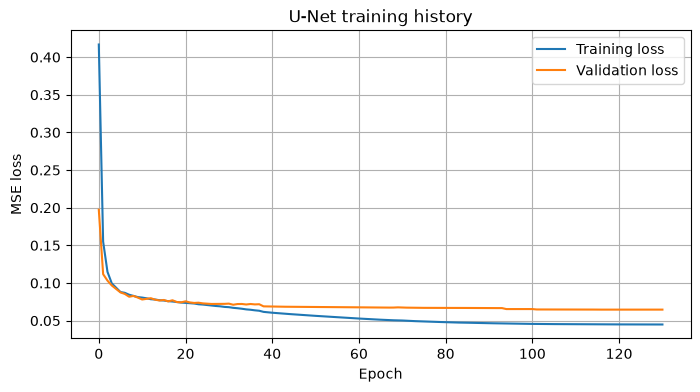

Model and normalization stats saved to: ../models/01_wall_to_near_wall_unet


In [17]:
# =========================================================
# Plot training history and save the model
# =========================================================

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("U-Net training history")
plt.legend()
plt.grid(True)
plt.show()

model_dir = Path("../models/01_wall_to_near_wall_unet")
model_dir.mkdir(exist_ok=True)

model_name = "unet1d_wall_to_nearwall"
unet_model.save(model_dir / f"{model_name}.keras")

np.savez_compressed(
    model_dir / f"{model_name}_normalization.npz",
    input_mean=input_mean, input_std=input_std,
    target_mean=target_mean, target_std=target_std
)

print("Model and normalization stats saved to:", model_dir)


# 13. Evaluate: U-Net vs the Linear-Law Baseline

Compared **separately per target** ($y^+=5$ and $y^+=10$), since we expect the
baseline to do noticeably worse at $y^+=10$.


In [18]:
# =========================================================
# Evaluate U-Net vs baseline, per target
# =========================================================

Y_val_pred_norm = unet_model.predict(X_val)
Y_val_pred_phys = Y_val_pred_norm * target_std + target_mean

unet_mae_per_target = np.mean(np.abs(Y_val_pred_phys - Y_val_phys), axis=(0, 1))

print(f"{'y+':>6}  {'U-Net MAE':>12}  {'Baseline MAE':>14}")
for target, u_mae, b_mae in zip(y_plus_targets, unet_mae_per_target, baseline_mae_per_target):
    print(f"{target:6.0f}  {u_mae:12.4f}  {b_mae:14.4f}")


 1/73 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

 9/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 

17/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

25/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

33/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

...

49/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

57/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

65/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


    y+     U-Net MAE    Baseline MAE
     5        0.0111         13.5757
    10        0.0360         27.1523


If the U-Net's advantage over the linear-law baseline is larger at $y^+=10$
than at $y^+=5$, that is direct evidence that $\tau_w(x)$ alone captures more
about the buffer-layer dynamics (beyond what the trivial linear law assumes)
than about the viscous sublayer itself -- worth checking explicitly.


# 14. Visualize One Validation Prediction


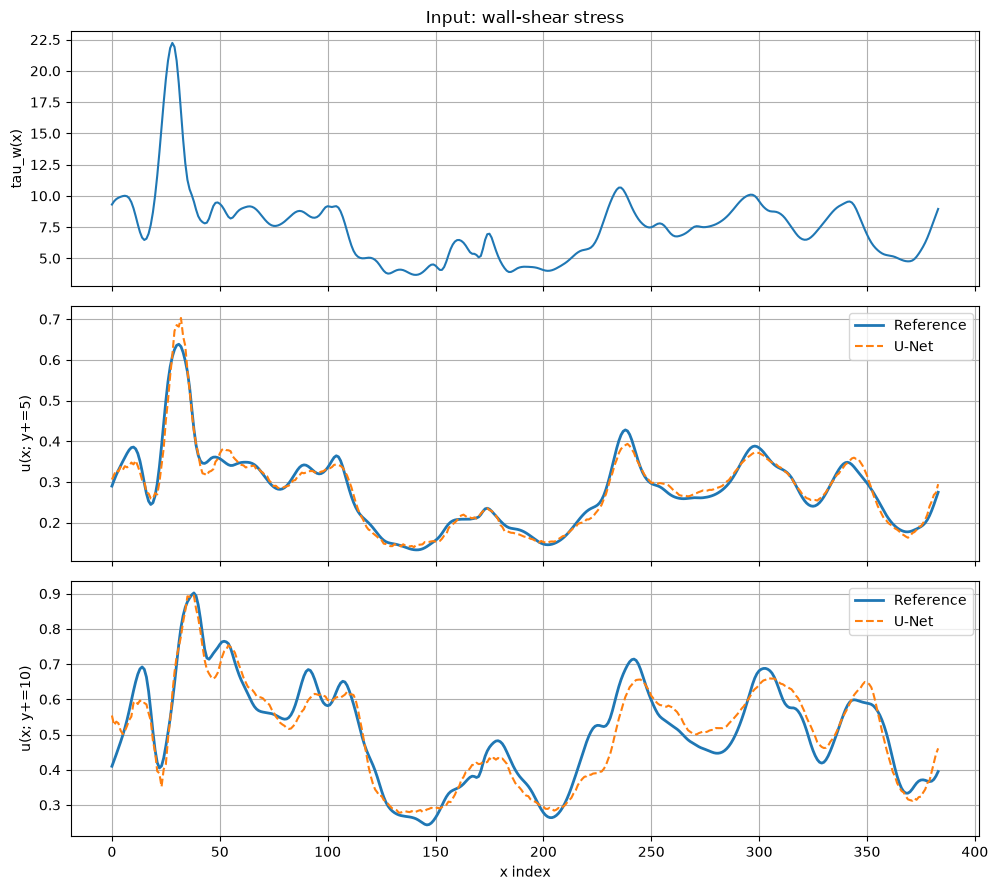

In [19]:
# =========================================================
# Visualize one validation sample: reference vs prediction vs baseline
# =========================================================

idx = -1

tau_w_phys = X_val[idx, :, 0] * input_std[0, 0, 0] + input_mean[0, 0, 0]
y_true = Y_val_phys[idx]
y_pred = Y_val_pred_phys[idx]
y_base = linear_law_predict(tau_w_phys[None, :], y_plus_targets)[0]

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

ax[0].plot(tau_w_phys)
ax[0].set_ylabel("tau_w(x)")
ax[0].set_title("Input: wall-shear stress")
ax[0].grid(True)

for j, target in enumerate(y_plus_targets):
    ax[j + 1].plot(y_true[:, j], label="Reference", linewidth=2)
    ax[j + 1].plot(y_pred[:, j], label="U-Net", linestyle="--")
    # ax[j + 1].plot(y_base[:, j], label="Linear-law baseline", linestyle=":")
    ax[j + 1].set_ylabel(f"u(x; y+={target:.0f})")
    ax[j + 1].legend()
    ax[j + 1].grid(True)

ax[-1].set_xlabel("x index")
fig.tight_layout()
plt.show()


# 15. Experiments

## Experiment 1 -- Push further from the wall

Add $y^+=20$, $30$, $50$ as additional targets (Section 6-7). The linear-law
baseline should break down much more severely beyond the buffer layer
($y^+ \gtrsim 30$, entering the log-law region) -- does the U-Net's advantage
over the baseline grow accordingly, or does its own accuracy also degrade?

---

## Experiment 2 -- Local vs nominal $u_\tau$

Section 6 uses the *nominal* $Re_\tau=125$ for the whole dataset to locate
$y^+$ grid indices. Instead, compute $u_\tau$ **per snapshot, per wall**
(`u_tau = sqrt(abs(tau_w))`, from Section 5's actual local wall-shear stress)
and use it to locate a genuinely instantaneous $y^+$ index per sample. Does
training on these (slightly different, snapshot-dependent) targets change the
results much?

---

## Experiment 3 -- Multiple z-planes

This notebook used a single fixed `z_index` (one plane per time snapshot). If
files for other `z_index` values are available, treat each as an additional,
independent sample (more data, still no z resolved as a spatial axis -- same
approach as for an off-wall version of this problem). Does more
data from different z-planes improve generalization more than, say, a bigger
model?

---

## Experiment 4 -- Gradient-based attribution

Pick one validation sample and one output position $x_i$ for the $y^+=10$
target. Use `tf.GradientTape()` to compute the gradient of
`Y_val_pred_norm[idx, i, 1]` with respect to the normalized input
`X_val[idx:idx+1]`. Plot the resulting gradient curve alongside $\tau_w(x)$ --
this shows which upstream/downstream wall-stress fluctuations most influence
that particular near-wall prediction, and can be extended into a full
gradient-SHAP analysis.

---

## Experiment 5 -- Does a much simpler model do just as well?

The 4-level U-Net (Section 11-12) may be more capacity than this fairly smooth
1D task needs. Compare it against a much smaller model (e.g. a single
`conv_block` with no pooling at all, or a small dense network) on the same
data. If the simpler model matches the U-Net's validation error, that is
useful evidence about how much of the U-Net's receptive field is actually
being used here.


# Experiment solutions
The five experiments of Section 15, solved with the notebook's own planes (`matched_files`), functions (`compute_tau_w_both_walls`, `y_plus_from_wall`, `create_unet_wall_to_nearwall`, `conv_block`) and training settings (Adam 1e-4 with clipnorm 1, MSE, batch 32, up to 300 epochs, early stopping patience 15, learning-rate halving patience 6). Errors are mean absolute errors (MAE) of `u` in the stored units, on validation data. **Experiment budget (mine):** every experiment model trains for at most 40 epochs with early stopping (the base allows 300 with its own early stopping; its received run stopped after about 180), and Experiment 3 compares two set-ups; variants are compared under the same budget. Compute plan: five trainings on the CPU, under 25 minutes.

In [20]:
import time, re
import pandas as pd
ex_dir = Path("../results/01_wall_to_near_wall_unet/exercises"); ex_dir.mkdir(exist_ok=True)

def ex_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6)]

def ex_fit(model, Xt, Yt, Xv, Yv, seed=0):
    tf.random.set_seed(seed); np.random.seed(seed)
    t0 = time.time()
    h = model.fit(Xt, Yt, validation_data=(Xv, Yv), epochs=max(5, int(40 * float(__import__('os').environ.get('EX_BUDGET_SCALE', '1')))), batch_size=32, callbacks=ex_callbacks(), verbose=0)
    return h, time.time() - t0

def ex_mae_phys(model, Xv_norm, Yv_phys, t_mean, t_std):
    pred = model.predict(Xv_norm, verbose=0) * t_std + t_mean
    return np.mean(np.abs(pred - Yv_phys), axis=(0, 1))

# file-level metadata from the names P125_83pi.<snapshot>.<z>.h5; sample 2k is the bottom wall of file k, 2k+1 the top wall
ex_snap = np.array([int(re.search(r"\.(\d+)\.(\d+)\.h5$", f.name).group(1)) for f in matched_files])
ex_z = np.array([int(re.search(r"\.(\d+)\.(\d+)\.h5$", f.name).group(2)) for f in matched_files])
print(f"{len(matched_files)} planes: {len(np.unique(ex_snap))} snapshots x {len(np.unique(ex_z))} z-planes")

# one pass over the planes to cache the profiles needed by Exercises 1-3
ex_yp_all = [5.0, 10.0, 20.0, 30.0, 50.0]
ex_idx_b = [int(np.argmin(np.abs(y_plus_from_wall(y_sample, "bottom") - t))) for t in ex_yp_all]
ex_idx_t = [int(np.argmin(np.abs(y_plus_from_wall(y_sample, "top") - t))) for t in ex_yp_all]
ex_re = float(attrs_sample["Re"]); ex_nu = 1.0 / ex_re
ex_tau, ex_u5, ex_ul = [], [], []   # tau_w, targets at nominal y+ (5 levels), targets at local y+ 5 and 10
ex_local_idx = []
for file_path in matched_files:
    with h5py.File(file_path, "r") as f:
        u = f["u"][:]; y = f["y"][:]
    tb, tt = compute_tau_w_both_walls(u, y)
    for wall, tau, idxs in (("bottom", tb, ex_idx_b), ("top", tt, ex_idx_t)):
        ex_tau.append(tau); ex_u5.append(np.stack([u[i, :] for i in idxs], axis=-1))
        # local friction velocity of this wall and snapshot: u_tau = sqrt(nu * |du/dy|), averaged over x
        u_tau_loc = np.sqrt(ex_nu * np.abs(tau).mean())
        y_wall = (y - y[0]) if wall == "bottom" else (y[-1] - y)
        yp_loc = y_wall * u_tau_loc / ex_nu
        il = [int(np.argmin(np.abs(yp_loc - t))) for t in (5.0, 10.0)]
        ex_local_idx.append(il); ex_ul.append(np.stack([u[i, :] for i in il], axis=-1))
ex_tau = np.array(ex_tau, np.float32)[..., None]; ex_u5 = np.array(ex_u5, np.float32); ex_ul = np.array(ex_ul, np.float32)
ex_local_idx = np.array(ex_local_idx)
print("cached:", ex_tau.shape, ex_u5.shape, ex_ul.shape)
print("check: cached y+=5,10 targets equal the notebook's Y:", bool(np.allclose(ex_u5[..., :2], Y)))

5777 planes: 107 snapshots x 60 z-planes


cached: (11554, 384, 1) (11554, 384, 5) (11554, 384, 2)
check: cached y+=5,10 targets equal the notebook's Y: True


## Experiment 1 — solution
Five targets, $y^+$ = 5, 10, 20, 30 and 50 (nominal $Re_\tau$ = 125 as in Section 6), with the same U-Net, normalisation scheme, split (`random_state=24`) and training settings. The linear-law baseline of Section 9 is evaluated at every level.

In [21]:
ex1_tm = ex_u5.mean(axis=(0, 1), keepdims=True); ex1_ts = ex_u5.std(axis=(0, 1), keepdims=True) + 1e-8
ex1_Xt, ex1_Xv, ex1_Yt, ex1_Yv = train_test_split(X_norm, (ex_u5 - ex1_tm) / ex1_ts, test_size=0.2, random_state=24, shuffle=True)
ex1_model = create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=5, base_filters=16)
ex1_hist, ex1_t = ex_fit(ex1_model, ex1_Xt, ex1_Yt, ex1_Xv, ex1_Yv)
ex1_Yv_phys = ex1_Yv * ex1_ts + ex1_tm
ex1_unet = ex_mae_phys(ex1_model, ex1_Xv, ex1_Yv_phys, ex1_tm, ex1_ts)
ex1_base = np.mean(np.abs(linear_law_predict(ex1_Xv[..., 0] * input_std[0, 0, 0] + input_mean[0, 0, 0], ex_yp_all) - ex1_Yv_phys), axis=(0, 1))
ex1 = pd.DataFrame(dict(y_plus=ex_yp_all, unet_mae=ex1_unet, baseline_mae=ex1_base, ratio=ex1_base / ex1_unet,
                        mean_abs_u=np.abs(ex1_Yv_phys).mean(axis=(0, 1))))
ex1.to_csv(ex_dir / "ex1_more_targets.csv", index=False); print(ex1.round(4)); print(f"{len(ex1_hist.history['loss'])} epochs, {ex1_t:.0f} s")
print("Result (Exercise 1): U-Net MAE " + ", ".join(f"y+={r.y_plus:.0f}: {r.unet_mae:.4f}" for r in ex1.itertuples())
      + "; baseline/U-Net ratio " + ", ".join(f"{r.ratio:.0f}" for r in ex1.itertuples()))

   y_plus  unet_mae  baseline_mae        ratio  mean_abs_u
0     5.0    0.0126     13.575700  1074.659668      0.2876
1    10.0    0.0391     27.152300   693.956970      0.5231
2    20.0    0.0767     54.308998   707.781982      0.7649
3    30.0    0.0809     81.465599  1007.289978      0.8555
4    50.0    0.0691    135.776901  1965.125854      0.9501
40 epochs, 201 s
Result (Exercise 1): U-Net MAE y+=5: 0.0126, y+=10: 0.0391, y+=20: 0.0767, y+=30: 0.0809, y+=50: 0.0691; baseline/U-Net ratio 1075, 694, 708, 1007, 1965


## Experiment 2 — solution
The local friction velocity is computed per snapshot and per wall from the local wall stress. Note on units: in this notebook $\tau_w$ is the wall gradient $\partial u/\partial y$ in the stored units, so the friction velocity is $u_\tau = \sqrt{\nu\,|\partial u/\partial y|}$ with $\nu = 1/Re$ (`Re` = 2100 is stored in every file); the experiment's shorthand `sqrt(abs(tau_w))` omits $\nu$, which would put $y^+$ off by a factor of about 46. With $\nu$ included the mean $Re_\tau$ matches the nominal 125. The $y^+$ = 5 and 10 indices then vary from sample to sample; the U-Net is retrained on these targets with everything else as in the base.

In [22]:
ex2_retau = np.array([np.sqrt(ex_nu * np.abs(t[:, 0]).mean()) / ex_nu * half_height for t in ex_tau])
ex2_tm = ex_ul.mean(axis=(0, 1), keepdims=True); ex2_ts = ex_ul.std(axis=(0, 1), keepdims=True) + 1e-8
ex2_Xt, ex2_Xv, ex2_Yt, ex2_Yv = train_test_split(X_norm, (ex_ul - ex2_tm) / ex2_ts, test_size=0.2, random_state=24, shuffle=True)
ex2_model = create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=2, base_filters=16)
_, ex2_t = ex_fit(ex2_model, ex2_Xt, ex2_Yt, ex2_Xv, ex2_Yv)
ex2_mae = ex_mae_phys(ex2_model, ex2_Xv, ex2_Yv * ex2_ts + ex2_tm, ex2_tm, ex2_ts)
ex2_changed = (ex_local_idx[:, 0] != ex_idx_b[0]) & (ex_local_idx[:, 0] != ex_idx_t[0])
ex2 = pd.DataFrame(dict(y_plus=[5, 10], unet_mae_nominal=unet_mae_per_target, unet_mae_local=ex2_mae))
ex2.to_csv(ex_dir / "ex2_local_utau.csv", index=False); print(ex2.round(4))
pd.DataFrame(dict(re_tau_local=ex2_retau)).describe().to_csv(ex_dir / "ex2_local_retau_stats.csv")
print(f"Result (Exercise 2): local Re_tau {ex2_retau.mean():.1f} ± {ex2_retau.std():.1f} (min {ex2_retau.min():.1f}, max {ex2_retau.max():.1f}); "
      f"MAE with local y+ targets {ex2_mae[0]:.4f} / {ex2_mae[1]:.4f} vs nominal {unet_mae_per_target[0]:.4f} / {unet_mae_per_target[1]:.4f} (y+=5 / 10)")

   y_plus  unet_mae_nominal  unet_mae_local
0       5            0.0111          0.0178
1      10            0.0360          0.0414
Result (Exercise 2): local Re_tau 126.1 ± 8.8 (min 97.7, max 153.4); MAE with local y+ targets 0.0178 / 0.0414 vs nominal 0.0111 / 0.0360 (y+=5 / 10)


## Experiment 3 — solution
The notebook's file pattern already matches every z-plane, so the base model was trained on all planes. The experiment is therefore run the other way round: compare a bigger model (`base_filters=32`) trained on a single z-plane per snapshot (z index 0) with the notebook's model size trained on all z-planes. To make the comparison honest, the split is **by snapshot** (the last 20 % of snapshot numbers are held out, all their z-planes), so no snapshot appears in both training and test; both models are scored on the same held-out samples.

In [23]:
ex_sample_snap = np.repeat(ex_snap, 2); ex_sample_z = np.repeat(ex_z, 2)
ex3_cut = np.quantile(np.unique(ex_snap), 0.8)
ex3_test = ex_sample_snap > ex3_cut
ex3_Yv = Y_norm[ex3_test]; ex3_Yv_phys = ex3_Yv * target_std + target_mean
ex3_rows = []
for name, mask, filters in (("single z-plane (z=0), 32 filters", (~ex3_test) & (ex_sample_z == 0), 32),
                            ("all z-planes, 16 filters", ~ex3_test, 16)):
    Xt, Yt = X_norm[mask], Y_norm[mask]
    Xt_t, Xt_v, Yt_t, Yt_v = train_test_split(Xt, Yt, test_size=0.15, random_state=24, shuffle=True)
    m = create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=2, base_filters=filters)
    h, t = ex_fit(m, Xt_t, Yt_t, Xt_v, Yt_v)
    mae = ex_mae_phys(m, X_norm[ex3_test], ex3_Yv_phys, target_mean, target_std)
    ex3_rows.append(dict(setup=name, n_train=int(mask.sum()), params=m.count_params(), epochs=len(h.history["loss"]), mae_y5=mae[0], mae_y10=mae[1], train_s=round(t)))
ex3 = pd.DataFrame(ex3_rows); ex3.to_csv(ex_dir / "ex3_zplanes_vs_capacity.csv", index=False); print(ex3)
print("Result (Exercise 3): held-out-snapshot MAE (y+=5 / 10): " + "; ".join(f"{r.setup}: {r.mae_y5:.4f} / {r.mae_y10:.4f} (n={r.n_train})" for r in ex3.itertuples()))

                              setup  n_train   params  epochs    mae_y5  \
0  single z-plane (z=0), 32 filters      170  2704898      40  0.038662   
1          all z-planes, 16 filters     9298   677122      40  0.012340   

    mae_y10  train_s  
0  0.070759       11  
1  0.040620      167  
Result (Exercise 3): held-out-snapshot MAE (y+=5 / 10): single z-plane (z=0), 32 filters: 0.0387 / 0.0708 (n=170); all z-planes, 16 filters: 0.0123 / 0.0406 (n=9298)


## Experiment 4 — solution
Gradient of the base model's normalised $y^+=10$ prediction at one position $x_i$ with respect to the normalised input $\tau_w(x)$, for the validation sample of Section 14 (`idx = -1`) and $x_i$ at the centre of the domain. Periodicity of the domain is respected in the plot by showing the offset $x - x_i$.

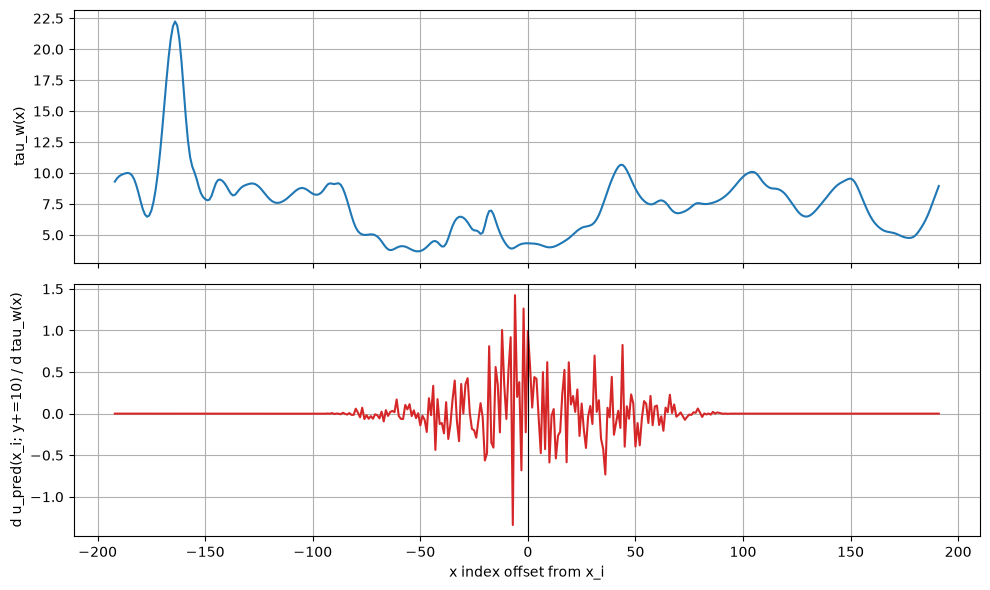

Result (Exercise 4): peak |gradient| at offset -6; half of the total |gradient| lies in the 27 most influential points; share upstream (x < x_i) 51 %, downstream 46 %


In [24]:
ex4_idx, ex4_i = len(X_val) - 1, padded_length // 2   # last validation sample (X_val[-1:0] would be empty)
ex4_x = tf.convert_to_tensor(X_val[ex4_idx:ex4_idx + 1])
with tf.GradientTape() as tape:
    tape.watch(ex4_x)
    ex4_out = unet_model(ex4_x, training=False)[0, ex4_i, 1]
ex4_g = tape.gradient(ex4_out, ex4_x).numpy()[0, :, 0]
ex4_off = np.arange(padded_length) - ex4_i
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(ex4_off, X_val[ex4_idx, :, 0] * input_std[0, 0, 0] + input_mean[0, 0, 0]); ax[0].set_ylabel("tau_w(x)"); ax[0].grid(True)
ax[1].plot(ex4_off, ex4_g, color="C3"); ax[1].axvline(0, color="k", lw=0.8); ax[1].set_ylabel("d u_pred(x_i; y+=10) / d tau_w(x)")
ax[1].set_xlabel("x index offset from x_i"); ax[1].grid(True); fig.tight_layout()
plt.savefig(ex_dir / "ex4_gradient_attribution.png", dpi=110); plt.show()
ex4_w = np.abs(ex4_g) / np.abs(ex4_g).sum()
ex4_half = int(np.searchsorted(np.cumsum(np.sort(ex4_w)[::-1]), 0.5)) + 1
ex4_up = ex4_w[ex4_off < 0].sum(); ex4_down = ex4_w[ex4_off > 0].sum()
pd.DataFrame(dict(offset=ex4_off, gradient=ex4_g)).to_csv(ex_dir / "ex4_gradient.csv", index=False)
print(f"Result (Exercise 4): peak |gradient| at offset {ex4_off[np.argmax(np.abs(ex4_g))]:+d}; half of the total |gradient| lies in the {ex4_half} most influential points; "
      f"share upstream (x < x_i) {100*ex4_up:.0f} %, downstream {100*ex4_down:.0f} %")

## Experiment 5 — solution
Two much smaller models on the notebook's data, split and training settings: (a) one `conv_block` (two 3-point convolutions, 16 filters) with no pooling, followed by a 1×1 output convolution, so each output sees only 5 neighbouring wall points; (b) a small dense network on the whole 384-point profile (384 → 128 → 768, reshaped to 384×2).

In [25]:
def ex_small_conv():
    i = tf.keras.layers.Input(shape=input_shape); x = conv_block(i, 16)
    m = tf.keras.Model(i, tf.keras.layers.Conv1D(out_channels, 1)(x), name="single_conv_block")
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0), loss="mse", metrics=["mae"]); return m
def ex_small_dense():
    i = tf.keras.layers.Input(shape=input_shape); x = tf.keras.layers.Flatten()(i)
    x = tf.keras.layers.Dense(128, activation="relu")(x); x = tf.keras.layers.Dense(padded_length * out_channels)(x)
    m = tf.keras.Model(i, tf.keras.layers.Reshape((padded_length, out_channels))(x), name="small_dense")
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0), loss="mse", metrics=["mae"]); return m
ex5_rows = [dict(model="U-Net (base)", params=unet_model.count_params(), mae_y5=unet_mae_per_target[0], mae_y10=unet_mae_per_target[1])]
for build in (ex_small_conv, ex_small_dense):
    m = build(); h, t = ex_fit(m, X_trn, Y_trn, X_val, Y_val)
    mae = ex_mae_phys(m, X_val, Y_val_phys, target_mean, target_std)
    ex5_rows.append(dict(model=m.name, params=m.count_params(), mae_y5=mae[0], mae_y10=mae[1], epochs=len(h.history["loss"]), train_s=round(t)))
ex5 = pd.DataFrame(ex5_rows); ex5.to_csv(ex_dir / "ex5_simpler_models.csv", index=False); print(ex5)
print("Result (Exercise 5): validation MAE (y+=5 / 10): " + "; ".join(f"{r.model} ({r.params} params): {r.mae_y5:.4f} / {r.mae_y10:.4f}" for r in ex5.itertuples()))

               model  params    mae_y5   mae_y10  epochs  train_s
0     U-Net (base)  677122  0.011080  0.036011     NaN      NaN
1  single_conv_block     882  0.014682  0.057649    40.0     18.0
2        small_dense  148352  0.029044  0.061799    40.0     11.0
Result (Exercise 5): validation MAE (y+=5 / 10): U-Net (base) (677122 params): 0.0111 / 0.0360; single_conv_block (882 params): 0.0147 / 0.0576; small_dense (148352 params): 0.0290 / 0.0618


## Summary of the experiment solutions
- **Experiment 1:** accuracy of the U-Net and of the linear law at five wall distances.
- **Experiment 2:** local versus nominal friction velocity for locating $y^+$, with the unit note on $\nu$.
- **Experiment 3:** single versus all z-planes, and a bigger model, under a snapshot-wise split.
- **Experiment 4:** which wall-stress points the $y^+=10$ prediction depends on.
- **Experiment 5:** how much of the U-Net's capacity this task uses.

The numbers are those printed in the `Result` lines above.

# Animation — the U-Net learning the near-wall velocity
Built from the snapshots collected **during the base training** (hook cell before the training cell; no second training run): after every epoch, the training and validation loss, the predicted $u(x; y^+=5)$ and $u(x; y^+=10)$ for the validation sample shown in Section 14, and the validation MAE per target. Dashboard: `../animations/01_training_dashboard.mp4`; last frame: `../animations/01_final_frame.png`.

In [26]:
import pickle
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = Path("../animations"); anim_dir.mkdir(exist_ok=True)
anim_true = Y_val_phys[-1]; pickle.dump(ANIM_CB.snaps, open(anim_dir / "01_snapshots.pkl", "wb"))

In [27]:
snaps = ANIM_CB.snaps; n_ep = snaps[-1]["epoch"]
allv = snaps[-1]["loss"] + snaps[-1]["val"]
ylims = [(anim_true[:, j].min() - 0.15 * np.ptp(anim_true[:, j]), anim_true[:, j].max() + 0.15 * np.ptp(anim_true[:, j])) for j in range(2)]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
def anim_draw(k):
    s = snaps[k]
    for a in axes.ravel(): a.clear()
    for j, ax in ((0, axes[0, 0]), (1, axes[1, 0])):
        ax.plot(anim_true[:, j], lw=2, label="Reference (DNS)"); ax.plot(s["pred"][:, j], "--", label="U-Net")
        ax.set_ylim(*ylims[j]); ax.set_ylabel(f"u(x; y+={y_plus_targets[j]:.0f})"); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
    axes[0, 0].set_title(f"One validation sample, epoch {s['epoch']}"); axes[1, 0].set_xlabel("x index")
    e = np.arange(1, len(s["loss"]) + 1)
    axes[0, 1].semilogy(e, s["loss"], label="training"); axes[0, 1].semilogy(e, s["val"], label="validation")
    axes[0, 1].set_xlim(0, n_ep); axes[0, 1].set_ylim(min(allv) * 0.8, max(allv) * 1.2); axes[0, 1].set_title("MSE loss (normalised targets)")
    axes[0, 1].set_xlabel("epoch"); axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3, which="both")
    m = np.array([x["mae"] for x in snaps[:k + 1]])
    axes[1, 1].semilogy([x["epoch"] for x in snaps[:k + 1]], m[:, 0], label="y+=5"); axes[1, 1].semilogy([x["epoch"] for x in snaps[:k + 1]], m[:, 1], label="y+=10")
    axes[1, 1].set_xlim(0, n_ep); axes[1, 1].set_ylim(np.array([x["mae"] for x in snaps]).min() * 0.8, np.array([x["mae"] for x in snaps]).max() * 1.2)
    axes[1, 1].set_title("Validation MAE of u per target"); axes[1, 1].set_xlabel("epoch"); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3, which="both")
    fig.suptitle("Stage 1 — 1-D U-Net: wall-shear stress -> near-wall velocity, base run (seed 0)"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / "01_final_frame.png", dpi=110)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / "01_training_dashboard.mp4", writer=FFMpegWriter(fps=10, bitrate=1800), dpi=100)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

Animation: 132 frames written


**What the animation shows.** Left: the reference near-wall velocity of one validation sample at $y^+=5$ (top) and $y^+=10$ (bottom) with the U-Net's prediction after each epoch, going from a flat line to the streaky profile. Top right: training and validation loss. Bottom right: the validation MAE of each target, showing when the $y^+=10$ target stops improving relative to $y^+=5$. The last frame is the final epoch of the notebook's run, which its own early stopping ended.

# Three-seed repeats
Every training of 15 minutes or less is repeated with the seeds 0, 1 and 2. **Seed 0 is the base run**: the notebook's own U-Net training above (seeds set in the import cell) and the experiment solutions (`seed=0`). For seeds 1 and 2, `tf.keras.utils.set_random_seed(seed)` sets the initial weights and the batch order; data, split, settings and device are unchanged. A training whose base run took longer than 15 minutes is not repeated, and the summary says so. One cell per seed, then a summary of the validation MAE of u (stored units).

In [28]:
# Three-seed repeats: helpers
import time
EX_TIMES = {"unet": None}
_h = history.history; EX_EPOCHS_BASE = len(_h["loss"])
def seed_fit(build, Xt, Yt, Xv, Yv, seed, epochs):
    tf.keras.utils.set_random_seed(seed); m = build(); t0 = time.time()
    h = m.fit(Xt, Yt, validation_data=(Xv, Yv), epochs=epochs, batch_size=32, callbacks=ex_callbacks(), verbose=0)
    return m, len(h.history["loss"]), round(time.time() - t0, 1)
def seed_run(seed):
    rows = []
    def add(part, config, maes, ep, t):
        for j, mae in enumerate(np.atleast_1d(maes)):
            rows.append(dict(seed=seed, part=part, config=config, target=j, mae=float(mae), epochs=ep, train_s=t))
        print(rows[-len(np.atleast_1d(maes)):], flush=True)
    m, ep, t = seed_fit(lambda: create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=out_channels, base_filters=16), X_trn, Y_trn, X_val, Y_val, seed, 300)
    EX_TIMES.setdefault(f"unet_seed{seed}", t)
    add("base", "U-Net, y+ = 5, 10", ex_mae_phys(m, X_val, Y_val_phys, target_mean, target_std), ep, t)
    m, ep, t = seed_fit(lambda: create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=5, base_filters=16), ex1_Xt, ex1_Yt, ex1_Xv, ex1_Yv, seed, 40)
    add("Exercise 1", "U-Net, y+ = 5, 10, 20, 30, 50", ex_mae_phys(m, ex1_Xv, ex1_Yv_phys, ex1_tm, ex1_ts), ep, t)
    m, ep, t = seed_fit(lambda: create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=2, base_filters=16), ex2_Xt, ex2_Yt, ex2_Xv, ex2_Yv, seed, 40)
    add("Exercise 2", "U-Net, local y+ = 5, 10", ex_mae_phys(m, ex2_Xv, ex2_Yv * ex2_ts + ex2_tm, ex2_tm, ex2_ts), ep, t)
    for name, mask, filters in (("single z-plane (z=0), 32 filters", (~ex3_test) & (ex_sample_z == 0), 32), ("all z-planes, 16 filters", ~ex3_test, 16)):
        Xt_t, Xt_v, Yt_t, Yt_v = train_test_split(X_norm[mask], Y_norm[mask], test_size=0.15, random_state=24, shuffle=True)
        m, ep, t = seed_fit(lambda: create_unet_wall_to_nearwall(input_shape=input_shape, output_channels=2, base_filters=filters), Xt_t, Yt_t, Xt_v, Yt_v, seed, 40)
        add("Exercise 3", name, ex_mae_phys(m, X_norm[ex3_test], ex3_Yv_phys, target_mean, target_std), ep, t)
    for build in (ex_small_conv, ex_small_dense):
        m, ep, t = seed_fit(build, X_trn, Y_trn, X_val, Y_val, seed, 40)
        add("Exercise 5", m.name, ex_mae_phys(m, X_val, Y_val_phys, target_mean, target_std), ep, t)
    return rows
seed_rows = []
for j, mae in enumerate(unet_mae_per_target): seed_rows.append(dict(seed=0, part="base", config="U-Net, y+ = 5, 10", target=j, mae=float(mae), epochs=EX_EPOCHS_BASE))
for j, mae in enumerate(ex1.unet_mae): seed_rows.append(dict(seed=0, part="Exercise 1", config="U-Net, y+ = 5, 10, 20, 30, 50", target=j, mae=float(mae)))
for j, mae in enumerate(ex2.unet_mae_local): seed_rows.append(dict(seed=0, part="Exercise 2", config="U-Net, local y+ = 5, 10", target=j, mae=float(mae)))
for r in ex3.itertuples():
    for j, mae in enumerate((r.mae_y5, r.mae_y10)): seed_rows.append(dict(seed=0, part="Exercise 3", config=r.setup, target=j, mae=float(mae), epochs=r.epochs, train_s=r.train_s))
for r in ex5.itertuples():
    if r.model != "U-Net (base)":
        for j, mae in enumerate((r.mae_y5, r.mae_y10)): seed_rows.append(dict(seed=0, part="Exercise 5", config=r.model, target=j, mae=float(mae), epochs=r.epochs, train_s=r.train_s))
print(len(seed_rows), "base-run (seed 0) rows; base U-Net epochs:", EX_EPOCHS_BASE)

17 base-run (seed 0) rows; base U-Net epochs: 131


In [29]:
# Seed 1
seed_rows += seed_run(1)

[{'seed': 1, 'part': 'base', 'config': 'U-Net, y+ = 5, 10', 'target': 0, 'mae': 0.011147651821374893, 'epochs': 153, 'train_s': 761.9}, {'seed': 1, 'part': 'base', 'config': 'U-Net, y+ = 5, 10', 'target': 1, 'mae': 0.03634663671255112, 'epochs': 153, 'train_s': 761.9}]


[{'seed': 1, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 0, 'mae': 0.012621835805475712, 'epochs': 40, 'train_s': 201.7}, {'seed': 1, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 1, 'mae': 0.038822241127491, 'epochs': 40, 'train_s': 201.7}, {'seed': 1, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 2, 'mae': 0.07666219770908356, 'epochs': 40, 'train_s': 201.7}, {'seed': 1, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 3, 'mae': 0.08043796569108963, 'epochs': 40, 'train_s': 201.7}, {'seed': 1, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 4, 'mae': 0.06859519332647324, 'epochs': 40, 'train_s': 201.7}]


[{'seed': 1, 'part': 'Exercise 2', 'config': 'U-Net, local y+ = 5, 10', 'target': 0, 'mae': 0.017409034073352814, 'epochs': 40, 'train_s': 200.9}, {'seed': 1, 'part': 'Exercise 2', 'config': 'U-Net, local y+ = 5, 10', 'target': 1, 'mae': 0.04011040925979614, 'epochs': 40, 'train_s': 200.9}]


[{'seed': 1, 'part': 'Exercise 3', 'config': 'single z-plane (z=0), 32 filters', 'target': 0, 'mae': 0.02542773447930813, 'epochs': 40, 'train_s': 10.6}, {'seed': 1, 'part': 'Exercise 3', 'config': 'single z-plane (z=0), 32 filters', 'target': 1, 'mae': 0.05422385782003403, 'epochs': 40, 'train_s': 10.6}]


[{'seed': 1, 'part': 'Exercise 3', 'config': 'all z-planes, 16 filters', 'target': 0, 'mae': 0.012185885570943356, 'epochs': 40, 'train_s': 168.2}, {'seed': 1, 'part': 'Exercise 3', 'config': 'all z-planes, 16 filters', 'target': 1, 'mae': 0.03974131867289543, 'epochs': 40, 'train_s': 168.2}]


[{'seed': 1, 'part': 'Exercise 5', 'config': 'single_conv_block', 'target': 0, 'mae': 0.014536825940012932, 'epochs': 40, 'train_s': 18.2}, {'seed': 1, 'part': 'Exercise 5', 'config': 'single_conv_block', 'target': 1, 'mae': 0.05578488111495972, 'epochs': 40, 'train_s': 18.2}]


[{'seed': 1, 'part': 'Exercise 5', 'config': 'small_dense', 'target': 0, 'mae': 0.02838362380862236, 'epochs': 40, 'train_s': 10.7}, {'seed': 1, 'part': 'Exercise 5', 'config': 'small_dense', 'target': 1, 'mae': 0.06120830774307251, 'epochs': 40, 'train_s': 10.7}]


In [30]:
# Seed 2
seed_rows += seed_run(2)

[{'seed': 2, 'part': 'base', 'config': 'U-Net, y+ = 5, 10', 'target': 0, 'mae': 0.011160979978740215, 'epochs': 300, 'train_s': 1495.6}, {'seed': 2, 'part': 'base', 'config': 'U-Net, y+ = 5, 10', 'target': 1, 'mae': 0.0362313874065876, 'epochs': 300, 'train_s': 1495.6}]


[{'seed': 2, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 0, 'mae': 0.012625383213162422, 'epochs': 40, 'train_s': 201.6}, {'seed': 2, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 1, 'mae': 0.03948363661766052, 'epochs': 40, 'train_s': 201.6}, {'seed': 2, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 2, 'mae': 0.07822097837924957, 'epochs': 40, 'train_s': 201.6}, {'seed': 2, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 3, 'mae': 0.0823691114783287, 'epochs': 40, 'train_s': 201.6}, {'seed': 2, 'part': 'Exercise 1', 'config': 'U-Net, y+ = 5, 10, 20, 30, 50', 'target': 4, 'mae': 0.0694921463727951, 'epochs': 40, 'train_s': 201.6}]


[{'seed': 2, 'part': 'Exercise 2', 'config': 'U-Net, local y+ = 5, 10', 'target': 0, 'mae': 0.017912447452545166, 'epochs': 40, 'train_s': 201.4}, {'seed': 2, 'part': 'Exercise 2', 'config': 'U-Net, local y+ = 5, 10', 'target': 1, 'mae': 0.04129414260387421, 'epochs': 40, 'train_s': 201.4}]


[{'seed': 2, 'part': 'Exercise 3', 'config': 'single z-plane (z=0), 32 filters', 'target': 0, 'mae': 0.03575915843248367, 'epochs': 40, 'train_s': 10.5}, {'seed': 2, 'part': 'Exercise 3', 'config': 'single z-plane (z=0), 32 filters', 'target': 1, 'mae': 0.06777063012123108, 'epochs': 40, 'train_s': 10.5}]


[{'seed': 2, 'part': 'Exercise 3', 'config': 'all z-planes, 16 filters', 'target': 0, 'mae': 0.012438657693564892, 'epochs': 40, 'train_s': 167.2}, {'seed': 2, 'part': 'Exercise 3', 'config': 'all z-planes, 16 filters', 'target': 1, 'mae': 0.039849262684583664, 'epochs': 40, 'train_s': 167.2}]


[{'seed': 2, 'part': 'Exercise 5', 'config': 'single_conv_block', 'target': 0, 'mae': 0.014819237403571606, 'epochs': 40, 'train_s': 18.2}, {'seed': 2, 'part': 'Exercise 5', 'config': 'single_conv_block', 'target': 1, 'mae': 0.05659810081124306, 'epochs': 40, 'train_s': 18.2}]


[{'seed': 2, 'part': 'Exercise 5', 'config': 'small_dense', 'target': 0, 'mae': 0.02947084978222847, 'epochs': 40, 'train_s': 10.6}, {'seed': 2, 'part': 'Exercise 5', 'config': 'small_dense', 'target': 1, 'mae': 0.06246616318821907, 'epochs': 40, 'train_s': 10.6}]


In [31]:
# Three-seed summary
seed_runs = pd.DataFrame(seed_rows); seed_runs.to_csv(ex_dir / "seeds_runs.csv", index=False)
seed_sum = seed_runs.groupby(["part", "config", "target"], sort=False).mae.agg(["mean", "std", "min", "max", "count"]).reset_index()
seed_sum.to_csv(ex_dir / "seeds_summary.csv", index=False)
print(seed_sum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

      part                           config  target   mean    std    min    max  count
      base                U-Net, y+ = 5, 10       0 0.0111 0.0000 0.0111 0.0112      3
      base                U-Net, y+ = 5, 10       1 0.0362 0.0002 0.0360 0.0363      3
Exercise 1    U-Net, y+ = 5, 10, 20, 30, 50       0 0.0126 0.0000 0.0126 0.0126      3
Exercise 1    U-Net, y+ = 5, 10, 20, 30, 50       1 0.0391 0.0003 0.0388 0.0395      3
Exercise 1    U-Net, y+ = 5, 10, 20, 30, 50       2 0.0772 0.0009 0.0767 0.0782      3
Exercise 1    U-Net, y+ = 5, 10, 20, 30, 50       3 0.0812 0.0010 0.0804 0.0824      3
Exercise 1    U-Net, y+ = 5, 10, 20, 30, 50       4 0.0691 0.0004 0.0686 0.0695      3
Exercise 2          U-Net, local y+ = 5, 10       0 0.0177 0.0003 0.0174 0.0179      3
Exercise 2          U-Net, local y+ = 5, 10       1 0.0409 0.0007 0.0401 0.0414      3
Exercise 3 single z-plane (z=0), 32 filters       0 0.0333 0.0070 0.0254 0.0387      3
Exercise 3 single z-plane (z=0), 32 filters